# Magnetic fit objective and holdout diagnostics

**Question:** How does a physical magnetic prediction enter a noise-weighted objective, and how do we keep held-out rows out of fitting?

**Level 2 — Prerequisites: the induced-prism forward-physics and spatial-holdout lessons; read time: 35 minutes.**


## Objectives

Build a real fit-fold objective from the closed survey protocol, an actual SimPEG/Geoana prism kernel, Gaussian uncertainty, and volume-normalized regularization. Check its derivative numerically, then score a frozen model on a separate validation fold. This lesson does not run or claim a magnetic inversion.

## Setup

Use the pinned Python 3.12 pipeline environment. The notebook installs nothing. The authored survey below is a protocol control, not a provider acquisition or field dataset.


Locate the repository and import the exact implementations. The helper fixture is explicitly protocol-only.

In [1]:
# Import the closed survey, actual objective assembly and development-fold scorer.
from pathlib import Path
import sys
import numpy as np

ROOT = Path.cwd()
while not (ROOT / 'data-pipeline').is_dir():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / 'data-pipeline'), str(ROOT / 'tests' / 'data')]
from magnetic_survey_support import encode, rehash, request
from magnetic_survey_json import parse_request
from magnetic_survey import plan_geometry
from magnetic_fit_assembly import assemble_magnetic_fit_objective, read_selected_likelihood
from magnetic_fold_score import model_q_sha256, score_magnetic_validation_fold


## Data

The fixture contains 288 receiver rows, a bounded 3D active-cell mesh, a uniform inducing-field declaration, zero protocol observations and diagonal conditional standard deviations. We set a nonzero starting susceptibility to exercise the physical response; that value is a prior start, not geological truth. Hashes are recomputed before parsing.


Create the nonzero-start protocol request and validate its closed schema before accessing numerical rows. The helper creates an authored fixture; it does not read a provider survey.


In [2]:
# Create an authored protocol request with a nonzero start model and rebind its descriptor hash.
survey = request()
survey['prior']['start_si']['data'] = [0.002] * len(survey['prior']['start_si']['data'])
rehash(survey, 'prior/start_si')
handle = parse_request(encode(survey))
print({'source_kind': handle.metadata()['source']['kind'], 'request_validated': True})


{'source_kind': 'authored_synthetic', 'request_validated': True}


Now plan receiver ownership from source identities and geometry alone. The plan seals the fit, validation and outer roles before likelihood values are read.


In [3]:
# Recompute the sealed geometry-only split and show its disjoint receiver counts.
plan = plan_geometry(handle)
meta = handle.metadata()
fit = np.asarray(plan['partition']['folds'][0]['fit_rows']['data'], dtype=np.int64)
validation = np.asarray(plan['partition']['folds'][0]['validation_rows']['data'], dtype=np.int64)
outer = np.asarray(plan['partition']['outer_rows']['data'], dtype=np.int64)
assert not (set(fit) & set(validation) or set(fit) & set(outer) or set(validation) & set(outer))
print({'fit_rows': len(fit), 'validation_rows': len(validation), 'sealed_outer_rows': len(outer),
       'geometry_seal': plan['identity']['seal_sha256']})

{'fit_rows': 144, 'validation_rows': 72, 'sealed_outer_rows': 72, 'geometry_seal': '0dd0b9f30a60f4165484caf1ec62a532589eebaea3d0db4ad2fd42b2954b7f15'}


Select only the fit likelihood after confirming the same geometry seal. This access returns the fit observation vector and its matching noise block, not validation or outer values.


In [4]:
# Read only authorized fit observations and the matching covariance principal block.
components = 3
fit_scalar_indices = (fit[:, None] * components + np.arange(components)).reshape(-1)
geometry_seal = plan['identity']['seal_sha256']
fit_document, fit_observations, fit_noise = read_selected_likelihood(
    handle, tuple(int(index) for index in fit_scalar_indices), geometry_seal
)
print({'fit_components': len(fit_observations), 'noise_kind': fit_document['noise']['kind'],
       'noise_shape': fit_noise.shape, 'all_fit_observations_zero': bool(np.all(fit_observations == 0))})

{'fit_components': 432, 'noise_kind': 'diagonal_sd', 'noise_shape': (432, 1), 'all_fit_observations_zero': True}


## Method

For secondary ENU data, the prism response is linear in susceptibility: `s(q)=G(0.01q)`, where `q=chi/0.01`. For selected fit rows the Gaussian objective is `phi_d = ||L^-1 (s(q)-d)||_2^2`; for diagonal SD, `L=diag(sigma)`, and for full covariance `LL^T=C` on the selected principal submatrix. The data gradient is `2 J_q^T C^-1(s-d)`. The regularizer uses cell-volume fractions and active-neighbor face terms with physical length scales. This code assembles and evaluates those terms; it does not choose beta or optimize q.

### Reading the weighted objective

The assembler is a forward-and-scoring component, not an optimizer. It builds a receiver-component sensitivity matrix from the declared cell geometry, inducing field and engine, then selects only the rows assigned to the fitting partition. For this lesson, the unknown vector is the dimensionless scaled susceptibility q=χ/0.01. That scaling keeps typical search coordinates near order one; it does not change the physical susceptibility, the receiver data, or the magnetic kernel. The current vector q starts at 0.2, corresponding to χ=0.002 SI. It is an initialization supplied by the protocol, not an estimate learned from the observations.

For selected residual r=s(q)−d and covariance C, the data term is the squared Mahalanobis distance. With independent standard deviations, the whitening operator divides each residual by its own σ. With correlated errors, the code extracts the covariance principal submatrix for the authorized rows and solves with its Cholesky factor. It does not whiten the full survey and then slice: that would allow fit rows to inherit a transformation involving held-out rows. The covariance describes conditional measurement-error assumptions. It is not a posterior covariance of q and does not quantify geological uncertainty.

$$\phi_d(q)=r(q)^T C^{-1}r(q)=\|L^{-1}r(q)\|_2^2,\qquad LL^T=C. $$

The local derivative for the linear secondary-field observable is J_q. Therefore the data gradient is 2J_q^T C^{-1}r. For the regularizer, active-cell volume fractions and neighboring-face geometry define physically scaled smallness and smoothness terms. The assembled result returns data and model terms separately; a calibration stage would combine them with a chosen β and optimize q. Here there is no selected β and no fitted model. A small data term alone would not establish geological uniqueness: potential-field sensitivity decays with source depth and spatial wavenumber, so different distributions can produce similar surface responses.

This separation matters when inspecting the printed score. A large objective can mean a poor model, a deliberately severe protocol control, an unrealistic covariance, or a unit mismatch. It is not interpretable until the observation quantity, units, mask, covariance and model lineage are read together. The synthetic request uses the secondary ENU vector in nT, with three components per receiver. It does not silently replace that vector with total-field anomaly, and the Jacobian ordering remains receiver-major then east, north, up. Mixing scalar TMI residuals with a three-component covariance would be a dimensional contract error, not a tuning choice.

### Why the split is geometric

The protocol assigns whole receiver locations to three disjoint roles before any amplitude is scored: 144 fit rows, 72 development-validation rows and 72 sealed outer rows. A row carries all three ENU components. The split is based on declared coordinates and stable identities, not on the sign or size of the magnetic response. Keeping components together avoids a false sample-size increase in which the east component of one station is fitted while its north and up components are called independent validation.

The fit objective is allowed to read only the 144 fit receivers. The development scorer then receives a frozen byte-level q and computes aggregate metrics for its 72 rows. It returns no observation, prediction or residual vectors and cannot choose β or candidates. The outer 72 rows are reserved for a later one-time evaluation after candidate selection and a final development refit. Plotting this partition makes its geometry inspectable, but it does not prove independent information: nearby stations can remain strongly correlated, and a spatial holdout may be easier than a distant or different-acquisition survey.

The current call is specifically a protocol fixture. Its observations are authored zeros and its nonzero start model is supplied to exercise the forward derivative and scoring boundary. The high held-out standardized quadratic score is therefore a useful negative diagnostic: the start response is incompatible with the zero control under its declared noise. It is not a measurement of a field inversion's predictive error. Changing the split, adding a noise realization, or selecting a smaller β after reading the outer result would change the experiment and invalidate its predeclared role.

### Inspect the sealed row plan

Plan the original survey, inspect the row assignment, and confirm that fit, validation and outer rows are disjoint. Geometry planning sees no amplitudes or noise values.

Assemble only fold 0 fit rows. The actual forward operator evaluates the user-declared mesh and field; the regularizer is the pinned SimPEG WLS implementation.

In [5]:
# Build the actual fold-scoped SimPEG/Geoana kernel, Gaussian term and WLS regularizer.
assembled = assemble_magnetic_fit_objective(handle, 0)
q = assembled['start_q']
fit_eval = assembled['objective'].evaluate(q)
reg_eval = assembled['regularizer'].evaluate(q)
print({'quantity': assembled['quantity'], 'fit_receivers': len(assembled['fit_rows']),
       'active_cells': len(q), 'chi_start_si': float(q[0] * 0.01),
       'phi_d': fit_eval['phi_d'], 'phi_m': reg_eval['phi'],
       'gradient_inf_q': float(np.linalg.norm(fit_eval['gradient_q'], ord=np.inf)),
       'claim': assembled['claim']})


{'quantity': 'secondary_enu', 'fit_receivers': 144, 'active_cells': 528, 'chi_start_si': 0.002, 'phi_d': 564455.5774028616, 'phi_m': 0.04000000000000001, 'gradient_inf_q': 99242.90528202611, 'claim': 'fit-fold objective assembly only; no inversion performed'}


Map the computed east-component prediction and its observed-minus-predicted fit residual at their actual ENU coordinates. The inputs are a protocol control, so these points must not be presented as a field survey.

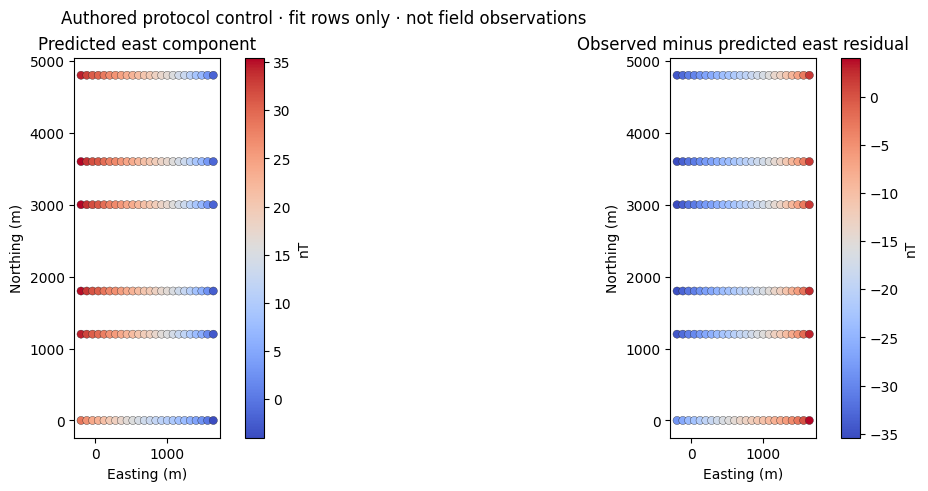

In [6]:
# Plot physical fit-station coordinates and computed E-component fit values in nT.
import matplotlib.pyplot as plt
xyz = np.asarray(meta['geometry']['receivers_m']['data'], dtype=np.float64).reshape(-1, 3)[assembled['fit_rows']]
pred = fit_eval['predicted_selected_nT'].reshape(-1, 3)
resid = fit_eval['residual_observed_minus_predicted_nT'].reshape(-1, 3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, values, title in zip(axes, (pred[:, 0], resid[:, 0]),
        ('Predicted east component', 'Observed minus predicted east residual')):
    image = ax.scatter(xyz[:, 0], xyz[:, 1], c=values, s=34, cmap='coolwarm', edgecolors='0.15', linewidths=.25)
    ax.set(title=title, xlabel='Easting (m)', ylabel='Northing (m)', aspect='equal')
    fig.colorbar(image, ax=ax, label='nT')
fig.suptitle('Authored protocol control · fit rows only · not field observations')
plt.show()


Check one model direction with a centered finite difference. The exact linear forward operator makes the data objective smooth here; the check validates the assembled derivative at this parameter point. The finite-difference step is held fixed for this single directional control, so its agreement with the analytic gradient does not characterize all coordinates, conditioning regimes, or the Hessian. A multi-step sweep is required before using this check to diagnose roundoff versus truncation error.

In [7]:
# Compare the analytic objective gradient with a centered difference along one q coordinate.
direction = np.zeros_like(q)
direction[0] = 1.0
step = 1e-5
phi_plus = assembled['objective'].evaluate(q + step * direction)['phi_d']
phi_minus = assembled['objective'].evaluate(q - step * direction)['phi_d']
fd = (phi_plus - phi_minus) / (2 * step)
analytic = float(fit_eval['gradient_q'] @ direction)
print({'central_difference': fd, 'analytic_directional_derivative': analytic,
       'absolute_difference': abs(fd - analytic)})
assert np.isclose(fd, analytic, rtol=2e-5, atol=2e-6)


{'central_difference': 845.1026980765163, 'analytic_directional_derivative': 845.1027000534544, 'absolute_difference': 1.9769381651713047e-06}


Freeze the model bytes first, then score only fold 0 validation rows. The result contains aggregate diagnostics, the model hash and geometry seal, but no observation, prediction or residual vectors.

In [8]:
# Freeze canonical model bytes before asking the isolated validation scorer for aggregate metrics.
frozen_hash = model_q_sha256(q)
score = score_magnetic_validation_fold(handle, 0, q, frozen_hash)
print(score)


{'schema': 'magnetic-development-fold-score-1', 'role': 'development-validation-only', 'fold_index': 0, 'geometry_seal_sha256': '0dd0b9f30a60f4165484caf1ec62a532589eebaea3d0db4ad2fd42b2954b7f15', 'model_q_f64le_sha256': '1398404c7c516bf13067d40bf785a523ec861d897b312ef187712cb003f856cb', 'receiver_count': 72, 'observation_count': 216, 'quantity': 'secondary_enu', 'phi_d': 263336.3622307736, 'mean_standardized_quadratic': 1219.1498251424705, 'residual_rms_nT': 17.458163027237934, 'cross_partition_dependence': 'declared_absent', 'contains_observation_vectors': False, 'candidate_selection_performed': False, 'outer_evaluation_performed': False}


## Results

**Answer:** The development-validation control reports mean standardized quadratic 1219.1498251424705 for the nonzero start against authored zero observations. This is a severe protocol mismatch, not predictive accuracy or a successful inversion. The analytic directional derivative differs from its centered finite-difference estimate by 1.9769381651713047 in the declared q direction; this checks one local derivative only. No β was selected, no candidate matrix ran, and the sealed partition was not evaluated.

The outputs below are computed from the product assembler, objective, regularizer and fold scorer. They demonstrate the behaviour of this fixed protocol control; they are not metrics for an acquired survey.


### Sensitivity and failure limits

The next sweep multiplies the same starting q by a scalar while leaving the survey, cell geometry, covariance and row partition unchanged. Because this lesson uses a linear secondary-field response, zero observations, and a quadratic regularizer, both φd and φm vary quadratically with that multiplier. The experiment checks the expected scaling of two independently returned objective terms; it does not find an optimal model. In particular, the minimum at zero is an immediate reminder that fitting the deliberately zero-valued fixture is not a useful magnetic interpretation problem.

$$s(aq)=a\,s(q),\quad d=0\;\Longrightarrow\;\phi_d(aq)=a^2\phi_d(q),\qquad \phi_m(aq)=a^2\phi_m(q). $$

A failure of the plotted ratios to follow this relation would point to an unintended nonlinear observable, changed mask, incorrect covariance selection, or regularizer scaling defect. A pass only supports those algebraic invariants for this fixture. It does not validate the model parameterization against real remanence, self-demagnetization, anisotropy, terrain, unmodelled regional fields or a mismatched inducing direction. Those are different physical hypotheses and require separately designed controls.

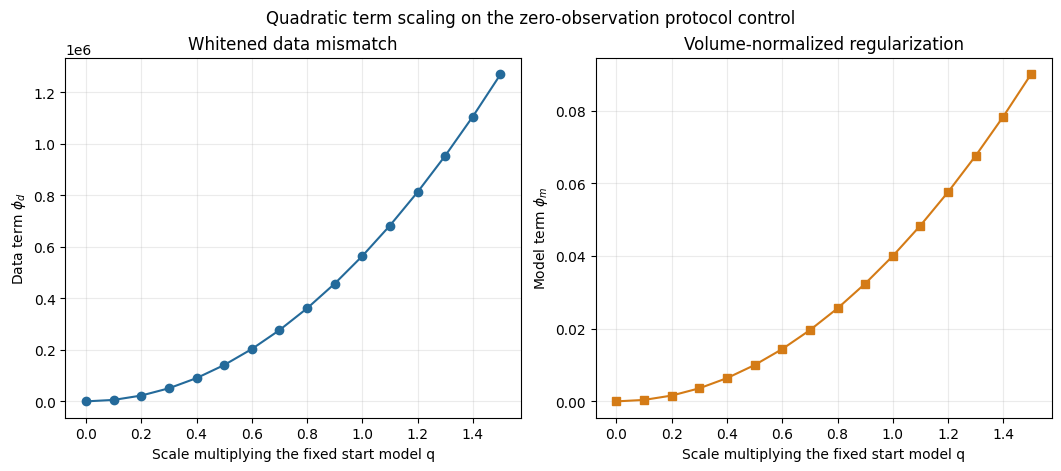

In [9]:
# Re-evaluate the product objective terms along one fixed scaled model direction.
scales = np.linspace(0.0, 1.5, 16)
phi_d_scale = []
phi_m_scale = []
for scale in scales:
    trial_q = scale * q
    phi_d_scale.append(assembled['objective'].evaluate(trial_q)['phi_d'])
    phi_m_scale.append(assembled['regularizer'].evaluate(trial_q)['phi'])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), constrained_layout=True)
axes[0].plot(scales, phi_d_scale, marker='o', color='#246a9a')
axes[0].set(xlabel='Scale multiplying the fixed start model q', ylabel=r'Data term $\phi_d$',
            title='Whitened data mismatch')
axes[1].plot(scales, phi_m_scale, marker='s', color='#d47b16')
axes[1].set(xlabel='Scale multiplying the fixed start model q', ylabel=r'Model term $\phi_m$',
            title='Volume-normalized regularization')
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle('Quadratic term scaling on the zero-observation protocol control')
plt.show()

Each panel has its own labelled vertical scale because the whitened data term is numerically much larger than the regularization term for this zero-observation fixture. Do not compare the visual heights across panels. Both curves are recomputed from production calls; with linear prediction, zero observations and quadratic regularization, each term scales with the square of q's multiplier. This demonstrates an algebraic control and its trivial zero-model minimum. It neither chooses β nor reports an inversion result.


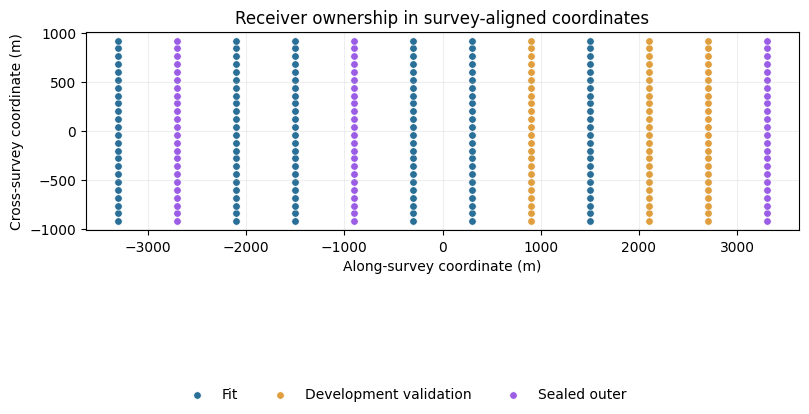

In [10]:
# Rotate display coordinates into survey-aligned axes without changing pairwise distances.
all_xyz = np.asarray(meta['geometry']['receivers_m']['data'], dtype=np.float64).reshape(-1, 3)
center_xy = all_xyz[:, :2].mean(axis=0)
centered_xy = all_xyz[:, :2] - center_xy
_, _, principal_axes = np.linalg.svd(centered_xy, full_matrices=False)
if principal_axes[0, 0] < 0:
    principal_axes[0] *= -1
local_xy = centered_xy @ principal_axes.T
fig, ax = plt.subplots(figsize=(9.2, 5.0))
for rows, label, color in ((fit, 'Fit', '#2a6f97'),
                           (validation, 'Development validation', '#e09f3e'),
                           (outer, 'Sealed outer', '#9b5de5')):
    ax.scatter(local_xy[rows, 0], local_xy[rows, 1], s=28, label=label,
               color=color, edgecolors='white', linewidths=0.35)
ax.set(xlabel='Along-survey coordinate (m)', ylabel='Cross-survey coordinate (m)',
       aspect='equal', title='Receiver ownership in survey-aligned coordinates')
ax.grid(alpha=0.2)
fig.subplots_adjust(bottom=0.24)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False)
plt.show()

The geometry is centered and rotated using an orthonormal basis computed from receiver coordinates, so pairwise distances and the equal physical scale are preserved. The horizontal axis follows the survey's dominant direction; the vertical axis measures cross-survey offset. Colors show the sealed row roles, not signal amplitude. This view can reveal block assignment and gaps, but it does not establish independent geological information or resolution.


### Use this method on your own data

Start from the strict survey contract and its local command in the magnetic-survey inversion design, not from the authored `request()` helper in this notebook. Preserve the original provider or user bytes and bind their SHA-256, byte count, citation, rights and complete-versus-subset scope. Declare ENU axes, metre coordinates, vertical datum, origin and the hash of any coordinate transform. State whether observations are `secondary_enu`, linear TMI, or exact total-field anomaly; these observables have different vector dimensions and Jacobians. Give each receiver a stable ID, provide the physical inducing field, active-cell geometry and a prior with explicit units and bounds. Attach either positive standard deviations with the exact observation shape or a symmetric positive-definite covariance whose component ordering is documented. Do not fill absent heights, epochs, datum, field direction or uncertainty with defaults.

The reproducible local route is to encode the closed request, parse it with `magnetic_survey_json.parse_request`, seal and inspect geometry with `magnetic_survey.plan_geometry`, then call `magnetic_fit_assembly.assemble_magnetic_fit_objective` only for a development fold. Before running the engine, inspect the parser's field-specific rejection and the partition receipt. Compare the independent forward values, test one gradient direction at multiple step sizes, and check that the fitting rows are exactly those in the sealed plan. Keep user data outside the repository and use the product's configured data root. The notebook's test fixture is not a substitute for this intake: it has no provider acquisition and contains no field truth.

At present this assembly lesson does not provide a complete accepted M04 result for arbitrary user surveys. The full candidate-by-fold β matrix, nested selection, development refit, immutable model freeze, one-time sealed evaluation, independent acquisition controls and result-bundle round trip remain distinct gates. A request may parse and a forward score may compute while the survey remains ineligible for inversion or online execution. Follow the failed status through the local run receipt; never rename an objective assembly as an inversion or publish its model as geology.

## Summary

This lesson traces closed-request parsing, geometry-only partitioning, fit-only likelihood access, objective assembly, a directional derivative check, and development-fold scoring. The protocol deliberately pairs zero observations with a nonzero starting model. Its high held-out score is a negative control. No inversion candidate was selected, no model was fit, and no field-geology conclusion follows.


## References

- SimPEG framework and gradient-based parameter estimation: https://doi.org/10.1016/j.cageo.2015.09.015
- Weighted least-squares formulation for geophysical inverse problems: https://doi.org/10.1109/36.17671
- Inverse Problems and Parameter Estimation, including nonuniqueness and resolution: https://doi.org/10.1016/C2015-0-02458-3
- Choclo physical prism kernels and coordinate conventions: https://www.fatiando.org/choclo/latest/
- Product implementation and M04 limitations: `data-pipeline/magnetic_fit_assembly.py`, `data-pipeline/magnetic_objective.py`, and `docs/design/features/m04-survey-inversion/validation.md`.